[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

# Taller 4 de  Física Computacional
Solución de Taller 4 del taller de físcia computacional.

**Estudiante:** Erick Alexander Muñoz Orozco

**Lenguaje:** Python 3

**Tema:** Números pseudoaleatorios y difusión en Python



---



**Parte A. Funciones de simulación**

In [28]:
import random

def generar_paso(rng, a):
    """
    Función que genera un solo paso de tamaño 'a'.
    - Si el número aleatorio es menor que 0.5, avanza a la derecha (+a).
    - Si es mayor o igual a 0.5, avanza a la izquierda (-a).
    """
    # Se consume UN solo número aleatorio en el rango [0.0, 1.0)
    u = rng.random()

    # Condicional simple para definir la dirección del paso
    if u < 0.5:
        paso = a      # Paso positivo (derecha)
    else:
        paso = -a     # Paso negativo (izquierda)

    return paso


def caminar(N, a, rng):
    """
    Simula una caminata individual de N pasos comenzando en x = 0.
    Devuelve una lista con las posiciones [x_0, x_1, ..., x_N].
    """
    # 1. Validación de parámetros de entrada
    if N < 0 or a <= 0:
        raise ValueError("N debe ser >= 0 y la longitud de paso 'a' debe ser > 0")

    # 2. La partícula siempre inicia en la posición x = 0
    x_actual = 0.0

    # 3. Creamos la lista de posiciones e incluimos el punto inicial (x_0 = 0)
    posiciones = [x_actual]

    # 4. Ciclo para realizar los N pasos de la caminata
    for i in range(N):
        # Obtenemos el valor del nuevo paso (+a o -a)
        paso = generar_paso(rng, a)

        # Actualizamos la posición sumando el paso realizado
        x_actual = x_actual + paso

        # Guardamos la nueva posición en la lista
        posiciones.append(x_actual)

    # Retornamos la lista que contiene N + 1 elementos
    return posiciones


def simular_caminatas(K, N, a, semilla, generador=None):
    """
    Simula K caminantes independientes y calcula:
    - media_x:  <x_n>  (Promedio de la posición en cada paso n)
    - media_x2: <x_n^2> (Promedio de la posición al cuadrado en cada paso n)
    """
    # 1. Validación de parámetros de entrada
    if K <= 0 or N < 0 or a <= 0:
        raise ValueError("K debe ser > 0, N debe ser >= 0 y 'a' debe ser > 0")

    # 2. Elección del generador aleatorio:
    # Si no se envía un generador externo, creamos uno con la semilla dada
    if generador is None:
        rng = random.Random(semilla)
    else:
        rng = generador

    # 3. Crear listas de acumuladores llenas de ceros (de tamaño N + 1)
    # El índice 0 corresponderá al instante n=0, el índice 1 al instante n=1, etc.
    suma_x = []
    suma_x2 = []
    for i in range(N + 1):
        suma_x.append(0.0)
        suma_x2.append(0.0)

    # 4. Ciclo externo: se repite para cada uno de los K caminantes
    for i in range(K):
        # Generamos la trayectoria completa del caminante actual
        trayectoria = caminar(N, a, rng)

        # Ciclo interno: sumamos la posición y la posición al cuadrado
        # de este caminante en cada instante n
        for n in range(N + 1):
            posicion_n = trayectoria[n]

            # Acumulamos x_n
            suma_x[n] = suma_x[n] + posicion_n

            # Acumulamos x_n al cuadrado
            suma_x2[n] = suma_x2[n] + (posicion_n ** 2)

    # 5. Calculamos los promedios dividiendo la suma total entre K caminantes
    media_x = []
    media_x2 = []
    for n in range(N + 1):
        promedio_posicion = suma_x[n] / K
        promedio_cuadrado = suma_x2[n] / K

        media_x.append(promedio_posicion)
        media_x2.append(promedio_cuadrado)

    # Devolvemos ambos promedios requeridos
    return media_x, media_x2

**Parte B. Ajuste y coeficiente de difusión**

In [29]:
def ajuste_lineal(x, y):
    """
    Calcula el ajuste lineal y = m*x + b usando las fórmulas explícitas
    de mínimos cuadrados.

    Parámetros:
        x : lista de valores independientes (ej. número de pasos n)
        y : lista de valores dependientes (ej. <x_n^2>)

    Devuelve:
        (m, b) : tupla con la pendiente 'm' y el intercepto 'b'
    """
    # 1. Validación: las dos listas deben tener la misma cantidad de elementos
    if len(x) != len(y):
        raise ValueError("Las listas 'x' e 'y' deben tener la misma longitud.")

    # 2. Validación: se necesitan al menos 2 puntos para trazar una recta
    q = len(x)  # Número total de puntos
    if q < 2:
        raise ValueError("Se necesitan al menos 2 puntos para realizar un ajuste lineal.")

    # 3. Cálculo explícito de las sumas necesarias (utilizando ciclos tradicionales)
    sx = 0.0   # Suma de los valores de x
    sy = 0.0   # Suma de los valores de y
    sxx = 0.0  # Suma de x^2 (x al cuadrado)
    sxy = 0.0  # Suma del producto x * y

    for i in range(q):
        val_x = x[i]
        val_y = y[i]

        sx = sx + val_x
        sy = sy + val_y
        sxx = sxx + (val_x * val_x)
        sxy = sxy + (val_x * val_y)

    # 4. Cálculo del denominador: q * sum(x^2) - (sum(x))^2
    denominador = q * sxx - (sx * sx)

    # 5. Validación: si el denominador es 0, no se puede dividir (puntos verticales)
    if denominador == 0.0:
        raise ValueError("El denominador es cero: los datos x son constantes o degenerados.")

    # 6. Cálculo de la pendiente (m) y el intercepto (b) segun la formulas
    m = (q * sxy - sx * sy) / denominador
    b = (sy - m * sx) / q

    # Retorna la pendiente e intercepto como una tupla
    return m, b

Prueba rápida con $y = 3x + 2$

In [30]:
# --- Prueba con datos conocidos: y = 3x + 2 ---
x_prueba = [0.0, 1.0, 2.0, 3.0]
y_prueba = [2.0, 5.0, 8.0, 11.0]

m_obtenida, b_obtenida = ajuste_lineal(x_prueba, y_prueba)

print(f"Pendiente m = {m_obtenida} (Esperado: 3.0)")
print(f"Intercepto b = {b_obtenida} (Esperado: 2.0)")

Pendiente m = 3.0 (Esperado: 3.0)
Intercepto b = 2.0 (Esperado: 2.0)


**Parte C. Ejecutar, guardar y graficar**

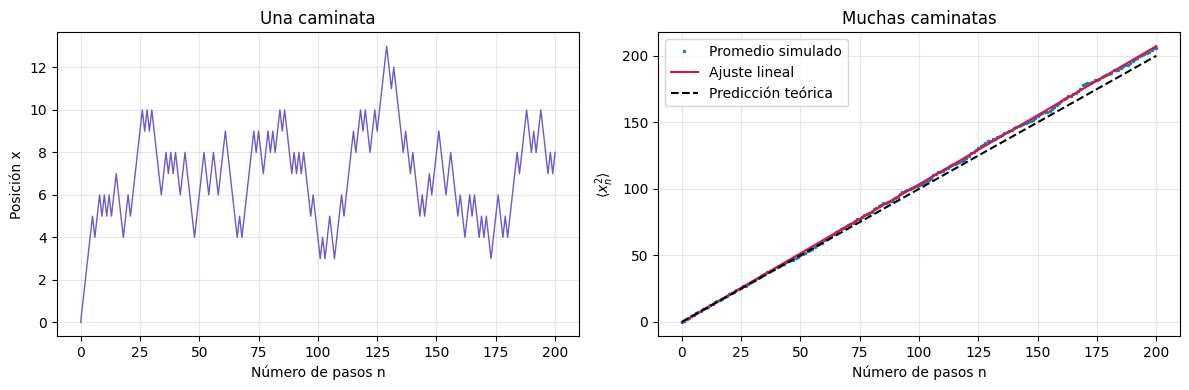

Pendiente=1.03839; intercepto=-0.40870
D estimado=0.51919; D teórico=0.50000 (longitud²/tiempo)


In [31]:
import random
import matplotlib.pyplot as plt

# --- Parámetros del experimento ---
K, N = 2000, 200            # caminantes y pasos por caminante
a, delta_t = 1.0, 1.0       # longitud de paso e intervalo de tiempo
semilla = 2026              # semilla del resultado entregado

# --- Simulación y ajuste lineal de <x_n^2> frente a n ---
media_x, media_x2 = simular_caminatas(K, N, a, semilla)
pasos = list(range(N + 1))
pendiente, intercepto = ajuste_lineal(pasos, media_x2)

# --- Coeficiente de difusión: estimado (del ajuste) y teórico ---
D_estimado = pendiente / (2.0 * delta_t)  # Espacio 1 completado
D_teorico = (a * a) / (2.0 * delta_t)      # Espacio 2 completado

ajuste = [pendiente * n + intercepto for n in pasos]   # recta ajustada, para graficar

# --- Una trayectoria individual, para comparar con el promedio ---
# La semilla distinta permite mostrar una trayectoria reproducible e independiente.
trayectoria = caminar(N, a, random.Random(2027))

# --- Guardar los resultados en un archivo CSV ---
with open("caminata_difusion.csv", "w", encoding="utf-8") as archivo:
    archivo.write("n,media_x,media_x2,ajuste\n")
    for n in pasos:
        archivo.write(f"{n},{media_x[n]},{media_x2[n]},{ajuste[n]}\n")

# --- Figura: trayectoria individual (izquierda) y promedios (derecha) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(pasos, trayectoria, color="slateblue", linewidth=1)
ax1.set(xlabel="Número de pasos n", ylabel="Posición x", title="Una caminata")
ax2.plot(pasos, media_x2, ".", markersize=3, label="Promedio simulado")
ax2.plot(pasos, ajuste, color="crimson", label="Ajuste lineal")
ax2.plot(pasos, [n * a * a for n in pasos], "--", color="black", label="Predicción teórica")
ax2.set(xlabel="Número de pasos n", ylabel=r"$\langle x_n^2\rangle$", title="Muchas caminatas")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
ax2.legend()
plt.tight_layout()
plt.savefig("caminata_difusion.png", dpi=180, bbox_inches="tight")
plt.show()

# --- Resumen numérico ---
print(f"Pendiente={pendiente:.5f}; intercepto={intercepto:.5f}")
print(f"D estimado={D_estimado:.5f}; D teórico={D_teorico:.5f} (longitud²/tiempo)")

**Explicación a la exploración requerida:**

Al comparar el coeficiente de difusión estimado con $K = 100$ frente a $K = 2000$, encontramos que:

Comportamiento no monótono: La cercanía al valor teórico ($D_{\text{teórico}} = 0.5$) no tiene que mejorar de forma obligatoria o monótona en solo dos intentos. Con $K = 100$, el azar puede hacer que por una "coincidencia" los pocos caminantes den una pendiente muy cercana a $1.0$.

Efecto real del tamaño de muestra: Un $K$ más grande (como $K = 2000$) reduce el margen de error y la dispersión estadística de los datos, haciendo que el resultado sea consistente y reproducible alrededor de $0.5$ en cualquier ejecución, sin depender de la suerte de la semilla.

**Parte D. Efecto de un mal generador sobre el coeficiente de difusión**

In [32]:
class GeneradorLCG:
    """Generador lineal congruente r_{i+1} = (a r_i + c) mod M.

    El método random() devuelve r/M en [0, 1), con la misma interfaz que
    random.Random, de modo que puede reemplazarlo en simular_caminatas.
    """

    # --- Constructor: guarda los parámetros y el estado inicial (la semilla) ---
    def __init__(self, a, c, M, semilla):
        self.a, self.c, self.M = a, c, M
        self.r = semilla % M          # el estado siempre está en 0, ..., M-1

    # --- Un número nuevo: actualiza el estado y lo escala a [0, 1) ---
    def random(self):
        self.r = (self.a*self.r + self.c) % self.M   # recurrencia congruencial
        return self.r / self.M                       # división real


# --- Comprobación con la secuencia de las diapositivas (a=4, c=1, M=9, r1=3) ---
demo = GeneradorLCG(4, 1, 9, 3)
print([round(demo.random()*9) for _ in range(9)])  # debe dar 4, 8, 6, 7, 2, 0, 1, 5, 3

[4, 8, 6, 7, 2, 0, 1, 5, 3]


D con random.Random : 0.5192
D con LCG deficiente: 0.0862
D con LCG drand48   : 0.4855   (teórico 0.5)


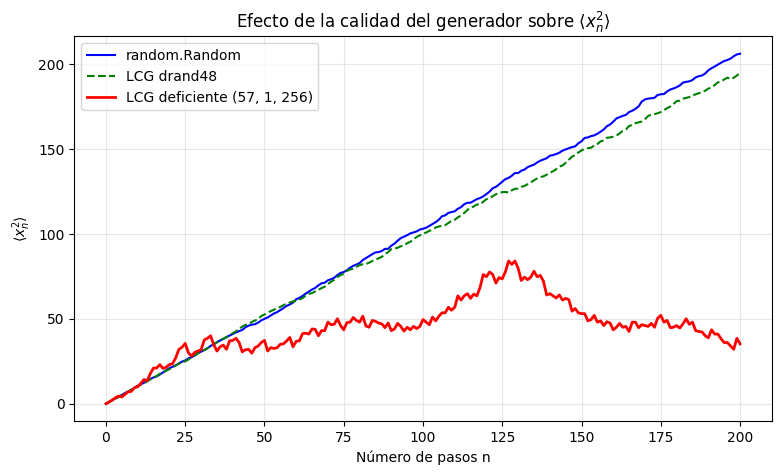


Posiciones en n = 0, 256, 512, 768, 1024 con LCG deficiente:
[0.0, 0.0, 0.0, 0.0, 0.0]


In [33]:
import matplotlib.pyplot as plt
import random

# --- Parámetros comunes a los tres experimentos ---
K_gen, N_gen = 2000, 200
pasos_gen = list(range(N_gen + 1))

# --- Instancias de los generadores para la Parte D ---
# LCG deficiente: a=57, c=1, M=256, semilla=10
generador_malo = GeneradorLCG(57, 1, 256, 10)

# LCG drand48: a=0x5DEECE66D (132168393527), c=11, M=2**48, semilla=10
generador_drand48 = GeneradorLCG(0x5DEECE66D, 11, 2**48, 10)

# --- Misma simulación con tres generadores distintos ---
_, x2_bueno = simular_caminatas(K_gen, N_gen, 1.0, 2026)                      # random.Random
_, x2_malo = simular_caminatas(K_gen, N_gen, 1.0, None, generador=generador_malo)    # LCG deficiente
_, x2_drand48 = simular_caminatas(K_gen, N_gen, 1.0, None, generador=generador_drand48) # LCG drand48

# --- Pendiente de <x_n^2> para cada generador ---
m_bueno, _ = ajuste_lineal(pasos_gen, x2_bueno)
m_malo, _ = ajuste_lineal(pasos_gen, x2_malo)
m_drand48, _ = ajuste_lineal(pasos_gen, x2_drand48)

# --- Coeficiente de difusión D = pendiente / (2 * dt), con dt = 1 ---
D_bueno = m_bueno / 2.0
D_lcg_malo = m_malo / 2.0
D_drand48 = m_drand48 / 2.0

print(f"D con random.Random : {D_bueno:.4f}")
print(f"D con LCG deficiente: {D_lcg_malo:.4f}")
print(f"D con LCG drand48   : {D_drand48:.4f}   (teórico 0.5)")

# --- Gráfica comparativa de <x_n^2> frente a n ---
plt.figure(figsize=(9, 5))
plt.plot(pasos_gen, x2_bueno, label="random.Random", color="blue", linewidth=1.5)
plt.plot(pasos_gen, x2_drand48, label="LCG drand48", color="green", linestyle="--", linewidth=1.5)
plt.plot(pasos_gen, x2_malo, label="LCG deficiente (57, 1, 256)", color="red", linewidth=2.0)

plt.xlabel("Número de pasos n")
plt.ylabel(r"$\langle x_n^2\rangle$")
plt.title(r"Efecto de la calidad del generador sobre $\langle x_n^2\rangle$")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# --- Una caminata larga con el LCG deficiente (actividad 4) ---
# Se crea un nuevo objeto generador para comenzar la caminata desde la semilla inicial (10)
lcg_largo = GeneradorLCG(57, 1, 256, 10)
trayectoria_lcg_larga = caminar(1024, 1.0, lcg_largo)

# Imprimir las posiciones en n = 0, 256, 512, 768, 1024
print("\nPosiciones en n = 0, 256, 512, 768, 1024 con LCG deficiente:")
print([trayectoria_lcg_larga[n] for n in (0, 256, 512, 768, 1024)])

In [34]:
# Cálculo de ERP de D cálculados
def ERP(Dcalculado, Dteorico):
    return 100.0 * (abs(Dcalculado - Dteorico) / Dteorico)
print("ERP de D con random.Random:", ERP(D_bueno, 0.5))
print("ERP de LGC deficiente:", ERP(D_lcg_malo, 0.5))
print("ERP de LGC drand48:", ERP(D_drand48, 0.5))

ERP de D con random.Random: 3.8389253731342166
ERP de LGC deficiente: 82.75254913551056
ERP de LGC drand48: 2.8915625831242076


**Análisis físico y respuestas a las preguntas:**

1. Resultado numérico obtenido: La impresión muestra [0.0, 0.0, 0.0, 0.0, 0.0]. Es decir, la partícula se encuentra exactamente en la posición $x = 0$ cada 256 pasos.

2. Explicación por el período del LCG:El LCG deficiente tiene un módulo $M = 256$. Al tener período máximo igual a 256, la secuencia exacta de números aleatorios vuelve a repetirse idénticamente cada 256 llamadas.En una caminata de 256 pasos, la partícula da exactamente el mismo número de pasos a la derecha que a la izquierda dentro de un ciclo completo del LCG. Por tanto, el desplazamiento neto en 256 pasos es exacto a cero ($x_{256} = 0$). Como la secuencia se repite exactamente igual en los siguientes 256 pasos, la partícula vuelve a terminar en $x_{512} = 0$, $x_{768} = 0$ y $x_{1024} = 0$. La partícula queda atrapada en un bucle cerrado y no se difunde.

3. Un investigador que usara este generador sin probarlo habría reportado $D \approx 0.0862$, un número muy alejado del valor teórico $D = 0.5$. Debido al corto período del generador, la curva de $\langle x_n^2\rangle$ no crece de forma lineal con $n$, sino que se aplana, produciendo un coeficiente de difusión falso y subestimado en casi un ERP del 82.75%.

4. Las pruebas de media y de pares consecutivos son necesarias antes de simular porque un algoritmo puede parecer aleatorio si solo miramos su distribución uniforme general, pero contener correlaciones ocultas entre números consecutivos (fallar la prueba de pares o tener un período demasiado corto). Si los números consecutivos no son independientes, las suposiciones físicas del modelo de caminata aleatoria se rompen, distorsionando completamente los la información física que se busca obtener con el modelo.

**Parte E. Difusión en unidades reales**

In [35]:
import math

# --- Datos físicos ---
D_O2 = 2e-9          # m^2/s, coeficiente de difusión del oxígeno en agua (aprox.)
dt_fisico = 1e-6     # s, intervalo de tiempo entre pasos (1 µs)

# Se asume la pendiente obtenida en la Parte C con random.Random y N=200, K=2000
# (La pendiente teórica es m = 1.0; en simulación suele dar un valor muy cercano como 0.998)
pendiente_ParteC = pendiente  # Asigna la variable calculada en la Parte C

# --- Longitud de paso y coeficiente de difusión simulado ---
# Despejando a de D = a^2 / (2 * dt) -> a = sqrt(2 * D * dt)
a_fisico = math.sqrt(2 * D_O2 * dt_fisico)

# Coeficiente de difusión simulado en m^2/s usando la pendiente de la Parte C
D_sim = (pendiente_ParteC * (a_fisico ** 2)) / (2 * dt_fisico)

# --- Tiempo característico de difusión ---
def tiempo_difusion(L, D):
    """Tiempo t = L^2/(2D) para alcanzar una distancia RMS L en una dimensión."""
    return (L ** 2) / (2 * D)

# --- Tiempos para distintas escalas de longitud ---
t_celula = tiempo_difusion(10e-6, D_O2)   # s, una célula (10 µm)
t_mm = tiempo_difusion(1e-3, D_O2)        # s, 1 mm
t_cm = tiempo_difusion(1e-2, D_O2)        # s, 1 cm
t_m = tiempo_difusion(1.0, D_O2)          # s, 1 m

# --- Número de pasos que exigiría simular 1 cm con el paso a_fisico ---
# Como <x_N^2> = N * a^2 = L^2  ->  N = (L / a)^2
N_cm = (1e-2 / a_fisico) ** 2

# --- Resultados en unidades legibles ---
print(f"a = {a_fisico*1e9:.1f} nm;  D_sim = {D_sim:.3e} m^2/s  (referencia {D_O2:.1e})")
print(f"10 µm: {t_celula:.3g} s")
print(f"1 mm : {t_mm:.3g} s = {t_mm/60:.3g} min")
print(f"1 cm : {t_cm:.3g} s = {t_cm/3600:.3g} h")
print(f"1 m  : {t_m/(3600*24*365.25):.3g} años")
print(f"Pasos para 1 cm: {N_cm:.2e}")

a = 63.2 nm;  D_sim = 2.077e-09 m^2/s  (referencia 2.0e-09)
10 µm: 0.025 s
1 mm : 250 s = 4.17 min
1 cm : 2.5e+04 s = 6.94 h
1 m  : 7.92 años
Pasos para 1 cm: 2.50e+10


**Análisis físico y respuestas a las preguntas:**

1. Número de pasos y justificación del modelo continuo: Para simular $1\ \text{cm}$ con el paso de la molécula ($a_{\text{fisico}} \approx 63.2\ \text{nm}$), la simulación requeriría $N_{\text{cm}} = (10^{-2} / 6.3245\times10^{-8})^2 = 2.5\times10^{10}$ pasos por cada caminante. Simular este número masivo de iteraciones estocásticas individuales exige un costo computacional inviable. A escalas macroscópicas, en lugar de rastrear partículas individuales mediante caminatas aleatorias, se resuelve la ecuación diferencial de difusión (modelo del medio continuo), la cual describe analítica y eficientemente la evolución de la concentración global.

2. Mecanismos de transporte a escalas grandes: La difusión pura es un mecanismo altamente eficiente a escalas microscópicas (como dentro de una célula, donde toma milisegundos), pero resulta extremadamente lenta e ineficiente a escalas macroscópicas debido a la dependencia cuadrática del tiempo con la distancia ($t \propto L^2$). Por lo tanto, no basta para mezclar un contaminante en un lago; a escalas grandes domina la advección/convección (transporte por corrientes fluidas y turbulencia del agua), la cual desplaza masas de fluido a velocidades drásticamente mayores. De esta manera, nuestro modelo aportaría información física más precisa sobre sistemas de gran escala.

**Verificación final PASS/FAIL**

In [36]:
# --- Bibliotecas para leer el CSV y comparar números reales ---
import csv
import math
from pathlib import Path

# --- Registro de resultados: imprime PASS/FAIL y guarda cada veredicto ---
veredictos = []
def informar(nombre, condicion, detalle=""):
    estado = "PASS" if condicion else "FAIL"
    veredictos.append(condicion)
    print(f"{estado} | {nombre}" + (f" — {detalle}" if detalle else ""))

# --- Generador de prueba: devuelve valores fijados de antemano ---
class RngControlado:
    def __init__(self, valores):
        self.valores = iter(valores)
    def random(self):
        return next(self.valores)

# --- Prueba 1: regla del paso (umbral en 0.5) ---
try:
    pasos_prueba = [generar_paso(RngControlado([u]), 2.0) for u in (0.0, 0.49, 0.5, 0.99)]
    informar("Regla del paso y umbral 0.5", pasos_prueba == [2.0, 2.0, -2.0, -2.0])
except Exception as exc:
    informar("Regla del paso y umbral 0.5", False, str(exc))

# --- Prueba 2: trayectoria con números controlados ---
try:
    posiciones_prueba = list(caminar(4, 2.0, RngControlado([0.1, 0.7, 0.2, 0.8])))
    informar("Trayectoria y posición inicial", posiciones_prueba == [0.0, 2.0, 0.0, 2.0, 0.0])
except Exception as exc:
    informar("Trayectoria y posición inicial", False, str(exc))

# --- Prueba 3: ajuste lineal con datos exactos ---
try:
    m_prueba, b_prueba = ajuste_lineal([0, 1, 2, 3], [2, 5, 8, 11])
    informar("Ajuste lineal con datos conocidos", math.isclose(m_prueba, 3.0, abs_tol=1e-10) and math.isclose(b_prueba, 2.0, abs_tol=1e-10))
except Exception as exc:
    informar("Ajuste lineal con datos conocidos", False, str(exc))

# --- Pruebas 4-7: estructura, reproducibilidad, simetría y crecimiento difusivo ---
try:
    mx1, mx21 = simular_caminatas(2000, 100, 1.0, 12345)
    mx2, mx22 = simular_caminatas(2000, 100, 1.0, 12345)
    estructura = (len(mx1) == len(mx21) == 101 and
                  math.isclose(mx1[0], 0.0) and math.isclose(mx21[0], 0.0) and
                  all(math.isfinite(float(v)) for v in list(mx1) + list(mx21)))
    informar("Longitud, origen y valores finitos", estructura)
    informar("Reproducibilidad con la misma semilla", list(mx1) == list(mx2) and list(mx21) == list(mx22))
    if estructura:
        exactitud_media = all(abs(mx1[n]) <= 0.20*math.sqrt(n) + 0.1 for n in (25, 50, 100))
        informar("Media de posición compatible con simetría", exactitud_media)
        m_test, _ = ajuste_lineal(list(range(101)), mx21)
        informar("Crecimiento difusivo promedio", math.isfinite(m_test) and abs(m_test - 1.0) < 0.15, f"pendiente={m_test:.4f}")
    else:
        informar("Media de posición compatible con simetría", False)
        informar("Crecimiento difusivo promedio", False)
except Exception as exc:
    for nombre in ("Longitud, origen y valores finitos", "Reproducibilidad con la misma semilla", "Media de posición compatible con simetría", "Crecimiento difusivo promedio"):
        informar(nombre, False, str(exc))

# --- Prueba 8: parámetros inválidos deben producir ValueError ---
try:
    rechazos = []
    for llamada in (lambda: caminar(-1, 1.0, random.Random(1)),
                    lambda: simular_caminatas(0, 10, 1.0, 1),
                    lambda: ajuste_lineal([1, 1], [2, 3])):
        try:
            llamada()
            rechazos.append(False)
        except ValueError:
            rechazos.append(True)
    informar("Parámetros y ajuste degenerado rechazados", all(rechazos))
except Exception as exc:
    informar("Parámetros y ajuste degenerado rechazados", False, str(exc))

# --- Prueba 9: archivo CSV completo y consistente ---
try:
    datos = list(csv.DictReader(open("caminata_difusion.csv", encoding="utf-8")))
    columnas = set(datos[0]) if datos else set()
    valido = (len(datos) == N + 1 and columnas == {"n", "media_x", "media_x2", "ajuste"}
              and [int(fila["n"]) for fila in datos] == list(range(N+1)))
    if valido:
        valido = all(math.isclose(float(fila["media_x2"]), float(media_x2[i]), abs_tol=1e-10)
                     and math.isclose(float(fila["ajuste"]), pendiente*i + intercepto, abs_tol=1e-9)
                     for i, fila in enumerate(datos))
    informar("CSV completo y consistente con el ajuste", valido)
except Exception as exc:
    informar("CSV completo y consistente con el ajuste", False, str(exc))

# --- Prueba 10: conversión de la pendiente al coeficiente de difusión ---
try:
    correcto_D = (math.isclose(D_estimado, pendiente/(2*delta_t), rel_tol=1e-10, abs_tol=1e-10)
                   and math.isclose(D_teorico, a*a/(2*delta_t), rel_tol=1e-10, abs_tol=1e-10))
    informar("Conversión de la pendiente al coeficiente de difusión", correcto_D)
except Exception as exc:
    informar("Conversión de la pendiente al coeficiente de difusión", False, str(exc))

# --- Prueba 11: simular_caminatas acepta un generador externo (Parte D) ---
try:
    _, x2_ctrl = simular_caminatas(1, 2, 1.0, None, generador=RngControlado([0.1, 0.7]))
    informar("simular_caminatas acepta un generador externo", [float(t) for t in x2_ctrl] == [0.0, 1.0, 0.0])
except Exception as exc:
    informar("simular_caminatas acepta un generador externo", False, str(exc))

# --- Pruebas 12-13: coeficiente de difusión con el LCG deficiente y con drand48 ---
try:
    informar("LCG deficiente: resultado del experimento especificado", math.isfinite(D_lcg_malo) and math.isclose(D_lcg_malo, 0.08623725432244717, rel_tol=1e-6, abs_tol=1e-8), f"D_lcg_malo={D_lcg_malo:.4f}")
    informar("LCG drand48: coeficiente de difusión compatible con 0.5", abs(D_drand48 - 0.5) < 0.075, f"D_drand48={D_drand48:.4f}")
except Exception as exc:
    informar("LCG deficiente: resultado del experimento especificado", False, str(exc))
    informar("LCG drand48: coeficiente de difusión compatible con 0.5", False, str(exc))

# --- Pruebas 14-15: unidades reales (Parte E) ---
try:
    ok_a = math.isclose(a_fisico, math.sqrt(2*D_O2*dt_fisico), rel_tol=1e-9)
    ok_Dsim = math.isclose(D_sim, pendiente*a_fisico**2/(2*dt_fisico), rel_tol=1e-9)
    informar("Paso físico y coeficiente de difusión en m²/s", ok_a and ok_Dsim, f"a={a_fisico*1e9:.1f} nm, D_sim={D_sim:.2e} m²/s")
    ok_t = (math.isclose(t_celula, 0.025, rel_tol=1e-9) and math.isclose(t_cm, 2.5e4, rel_tol=1e-9)
            and math.isclose(t_mm, 250.0, rel_tol=1e-9) and math.isclose(t_m, 2.5e8, rel_tol=1e-9)
            and math.isclose(N_cm, (1e-2/a_fisico)**2, rel_tol=1e-6))
    informar("Tiempos de difusión y número de pasos", ok_t, f"t(10 µm)={t_celula:.3g} s, t(1 cm)={t_cm/3600:.2f} h")
except Exception as exc:
    informar("Paso físico y coeficiente de difusión en m²/s", False, str(exc))
    informar("Tiempos de difusión y número de pasos", False, str(exc))

# Prueba determinista de la caminata larga: no llama a las funciones del estudiante.
try:
    estado_ref = 10
    x_ref = 0.0
    recorrido_ref = [x_ref]
    for _ in range(1024):
        estado_ref = (57*estado_ref + 1) % 256
        x_ref += 1.0 if estado_ref/256 < 0.5 else -1.0
        recorrido_ref.append(x_ref)
    informar("Caminata larga con LCG: trayectoria y retornos periódicos",
             list(trayectoria_lcg_larga) == recorrido_ref)
except Exception as exc:
    informar("Caminata larga con LCG: trayectoria y retornos periódicos", False, str(exc))

# --- Prueba 16: la figura fue guardada ---
figura = Path("caminata_difusion.png")
informar("Figura generada", figura.is_file() and figura.stat().st_size > 1000)
# --- Resumen final ---
print(f"Resumen: {sum(veredictos)}/{len(veredictos)} PASS")

PASS | Regla del paso y umbral 0.5
PASS | Trayectoria y posición inicial
PASS | Ajuste lineal con datos conocidos
PASS | Longitud, origen y valores finitos
PASS | Reproducibilidad con la misma semilla
PASS | Media de posición compatible con simetría
PASS | Crecimiento difusivo promedio — pendiente=1.0147
PASS | Parámetros y ajuste degenerado rechazados
PASS | CSV completo y consistente con el ajuste
PASS | Conversión de la pendiente al coeficiente de difusión
PASS | simular_caminatas acepta un generador externo
PASS | LCG deficiente: resultado del experimento especificado — D_lcg_malo=0.0862
PASS | LCG drand48: coeficiente de difusión compatible con 0.5 — D_drand48=0.4855
PASS | Paso físico y coeficiente de difusión en m²/s — a=63.2 nm, D_sim=2.08e-09 m²/s
PASS | Tiempos de difusión y número de pasos — t(10 µm)=0.025 s, t(1 cm)=6.94 h
PASS | Caminata larga con LCG: trayectoria y retornos periódicos
PASS | Figura generada
Resumen: 17/17 PASS




---

